In [34]:
from langgraph.graph import StateGraph ,START,END
from langchain_huggingface import HuggingFaceEndpoint , ChatHuggingFace
from typing import TypedDict , Annotated
from dotenv import load_dotenv
from pydantic import Field , BaseModel

import operator
from langchain_core.tools import tool
from langchain_core.output_parsers import PydanticOutputParser
from langchain_core.prompts import PromptTemplate
from langchain_core.exceptions import OutputParserException
from langchain_core.messages import BaseMessage
from langchain_core.messages import HumanMessage, AIMessage
from langgraph.graph import add_messages
from langchain_groq import ChatGroq
from langgraph.prebuilt import ToolNode,tools_condition
from langchain_core.tools import tool
import os
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.messages import SystemMessage
load_dotenv()  # Load environment variables from .env file


True

In [35]:
model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)
class chatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

@tool
def arithmatic_op(a: float, b: float, opr: str) -> float:
    """Perform arithmetic: add, sub, mul, or div."""
    if opr == "add":
        return a + b
    elif opr == "sub":
        return a - b
    elif opr == "mul":
        return a * b
    elif opr == "div":
        if b == 0:
            raise ValueError("Cannot divide by zero")
        return a / b
    else:
        raise ValueError(f"Unsupported operator: {opr}")
search_tool=DuckDuckGoSearchRun(region="us-en")

tools=[arithmatic_op,search_tool]
llm_with_tools=model.bind_tools(tools)


In [36]:
def chatbot(state:chatState):
    """LLM node that may answer the question or use toolNode"""
    message=state["messages"]
    result=llm_with_tools.invoke(message)
    return {'messages':[result]}
toolnode=ToolNode(tools)


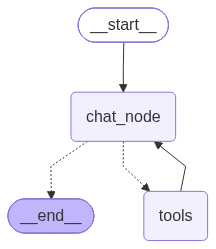

In [37]:
graph=StateGraph(chatState)
graph.add_node("chat_node",chatbot)
graph.add_node("tools",toolnode)
graph.add_edge(START,"chat_node")
graph.add_conditional_edges("chat_node",tools_condition)
graph.add_edge("tools", "chat_node")

workflow=graph.compile()
workflow

In [16]:
workflow.invoke({"messages":[HumanMessage(content="who are you")]})["messages"][-1].content


'I’m ChatGPT, an AI language model created by OpenAI. I’m designed to understand and generate human‑like text, answer questions, help with writing, solve problems, brainstorm ideas, and much more. Think of me as a versatile virtual assistant you can chat with about a wide range of topics. How can I help you today?'

In [41]:
# workflow.invoke({"messages":[SystemMessage(content="""
# You are a helpful assistant.

# Formatting rules:
# - Use plain, readable text.
# - Do not use Unicode escape sequences such as \\u202f.
# - Avoid unnecessary special characters.
# - Use simple arithmetic notation, such as 5 * 100 = 500.
# - Use Markdown only when it improves readability.
# - Keep answers concise.
# """),HumanMessage(content="answer 5 *  100 and tell me which tool do you use")]})["messages"][-1].content
response = workflow.invoke({
    "messages": [
        SystemMessage(content="""
You are a helpful assistant.
Use plain text and ordinary spaces.
Avoid unusual Unicode whitespace and unnecessary formatting.
Keep answers concise.
"""),
        HumanMessage(
            # content="Answer 5 * 100 and tell me which tool you use."
            content="what is the current score of zimbabwe vs bangladesh cricket match on 17 oct 2026"
        )
    ]
})

answer = response["messages"][-1].content
answer = answer.replace("\u202f", " ").replace("\u00a0", " ")

print(answer)

DDGSException: DNSError: DNSError('error sending request for url (https://wt.wikipedia.org/w/api.php?action=opensearch&profile=fuzzy&limit=1&search=Zimbabwe%20vs%20Bangladesh%20live%20score%2017%20October%202026) > error resolving DNS > DNS error: no records found for Query { name: Name("wt.wikipedia.org."), query_type: A, query_class: IN }')

In [ ]:
workflow.invoke({"messages":[HumanMessage(content="what is the current time in delhi?")]})["messages"][-1].content
